# E122: does the broad Adam copy fail because of its damage or its recipe?

## The answer

We could not tell. We copied an Adam fine-tune stopped at the LoRA's level of damage, and a LoRA trained on to the
Adam's level, into the decomposition. Neither copy landed clearly on one side of the adversarial check's lines. As a
lean only, both copies moved with damage: less damage, lower ratio. Separately, a copy started from the fine-tune's
least-squares split failed far worse than the standard copy, at about 9.4 against 2.2. It fitted the fine-tuned model
just as well, so fitting the fine-tune and staying faithful come apart here.


## What we were trying to test

**Teacher training** copies a fine-tuned model into the decomposition. Only the subcomponents' U and V train, with Γ and
Δ frozen, on the KL divergence from the fine-tuned model. On the broad lowercase task, the copy of a full-matrix Adam
fine-tune fails VPD's adversarial check, and the copy of a rank-8 LoRA fine-tune of the same task passes.

Those two fine-tunes differ in two ways at once. One is the **recipe**: Adam changes all 24 matrices freely, while the
LoRA changes each by a rank-8 product. The other is the **damage**, $\mathrm{KL}(W_0 \,\|\, W_0 + \delta W)$ averaged
over every position of 64 plain Pile rows: how much the update changes predictions on ordinary text. The Adam
fine-tune's damage is about 0.24 nats, the LoRA's about 0.12.

So we crossed them, and copied each new fine-tune with the same recipe:

- **Cell 1**: the Adam fine-tune stopped at step 20, where its damage matches the LoRA's. If this copy fails, Adam's
  shape fails even at low damage.
- **Cell 2**: the LoRA trained on fresh rows to step 2,400, where its damage matches the Adam's. If this copy passes,
  the LoRA's shape passes even at high damage.
- **Cell 3**: the full Adam fine-tune again, but with teacher training started from its **least-squares split**, the
  least-norm $(dU, dV)$ with $dU\,V^\top + U\,dV^\top \approx \delta W$, instead of from W₀'s U and V. This start
  already reproduces the fine-tuned model, so it asks whether the failure is only where training from W₀ happens to go.

Each cell's damage had to fall in a band of ±0.028 nats around its target, set from this job's own fine-tunes.

**How each state is read.** The check is VPD's adversary in the authors' code: it searches for the masks on
the subcomponents that make the decomposition's output differ most from the target model's. The **ratio** is that
worst-case KL over the unchanged decomposition's, W₀'s, on the same rows. 1 means as faithful as W₀. Pass is 1.40 or
below, fail 1.61 or above; in between is neither. Each state is read on two sets of 256 Pile rows, A and B, and a cell
counts only if both sets agree. Each cell's **do-nothing**, its fine-tune's change left in Δ, must fail, or the check
had no power on that update.

**Controls, run first.** W₀ and E39's two saved copies reproduced their earlier readings on this card exactly. The Adam
fine-tune, copied again in this job, failed as it must, at 1.91.


## What we expected, and why

- **Cell 1 passes**, with low confidence. On these rows every state with damage over 0.2 had failed and every one
  under 0.06 had passed, which points at damage. But full-matrix SGD copies at a damage near the LoRA's had failed one
  set and passed the other, so a mixed result was also likely.
- **Cell 2 fails**, with medium-low confidence: everything above damage 0.2 had failed so far, though the LoRA's pass
  was the one result no earlier explanation had removed.
- **Cell 3**: no lean. On the emoticon task, a start from the least-squares split kept teacher training close to the
  fine-tune. But a copy from a scaled adjoint split had drifted into failing as it took on the full damage.
- **Where the excess sits**: Fable expected the Adam copy's excess to sit more at positions where the task changes the
  prediction than the LoRA copy's.

Damage is the cause if cell 1 passes and cell 2 fails; the recipe is the cause if the reverse.


## Did crossing damage and recipe separate the two causes?

The figure plots every state's ratio against its damage, set A on the left and set B on the right. Blue is the Adam
recipe, orange the LoRA, green the least-squares split start and its copy. Filled marks are copies; open marks are
do-nothings, read on set A only. The dotted arrows go from each saved copy to its crossed cell.


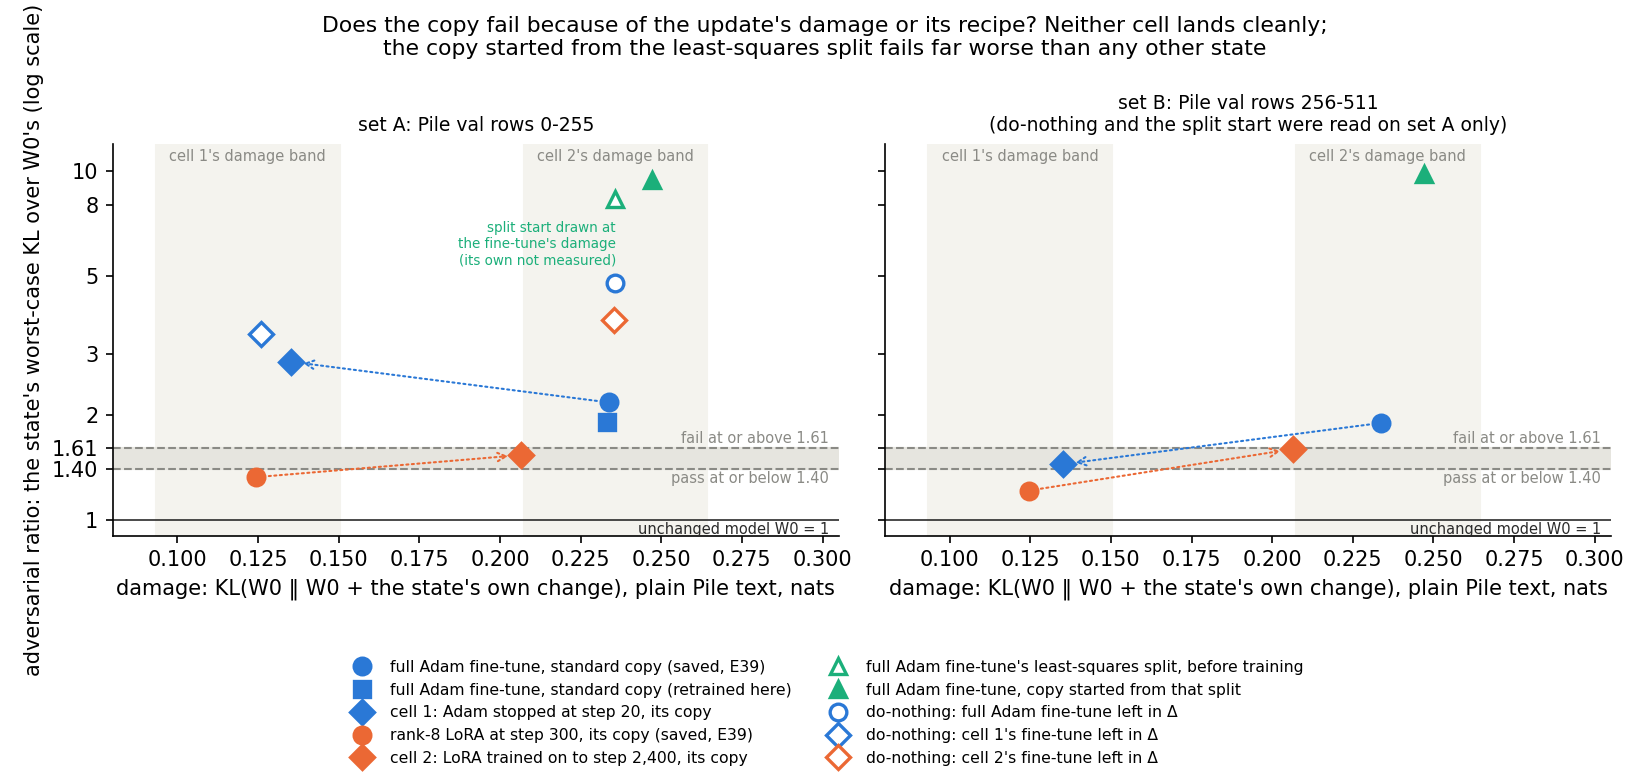

In [1]:
from IPython.display import Image

Image("../experiments/damage_crossed/figures/ratio_vs_damage.png", width=900)


**Reading it.** No: neither crossed copy landed on one side of the lines on both sets, so the filed rule gives no call.
The Adam fine-tune stopped at step 20 failed on set A at 2.84 and sat just above the pass line on set B at 1.44. The
LoRA trained to step 2,400 sat between the lines on both sets, at 1.53 and 1.60. Its copy's damage also fell just below
its band, so it is off target as well.

Read as a lean, both arrows point the same way. Raising the LoRA's damage moved its copy from a pass up to the fail
line. Lowering the Adam's damage lowered its copy on set B. On set A it rose, but only on one block of 128 rows. On that
block the step-20 fine-tune left in Δ reads 5.3, while on the other block it reads 1.3, a pass. Over the four blocks,
the low-damage Adam copy reads lower than the full one on three. The do-nothings all fail, at 3.4 to 4.8, so the check
had power on every update.


## Does starting from the least-squares split give a faithful copy?

**Reading it.** No: the green triangles in the figure above sit far above every other state. The split start alone reads
8.3 on set A, worse than leaving the whole change in Δ, which reads 4.8. After teacher training it reads 9.4 on set A
and 9.8 on set B. The standard copy of the same fine-tune, trained from W₀'s U and V, reads 1.9 to 2.2.

The split start does reproduce the fine-tuned model. Teacher training's loss at its first step was 0.021, against 0.29
from W₀'s start. At the end both copies are about equally close to the fine-tuned model on held-out lowercase rows, with
teacher gaps of 0.010 and 0.012 nats. So on this fine-tune, matching the fine-tuned model and being faithful under the
adversary pull apart. Training from the split did not move the copy toward faithfulness either.

How close the copies sit to the fine-tune in weights was not measured on this task. The earlier result that a split
start stays close in weights was on the narrow emoticon task.


## Where does the adversary find its excess?

Every read also kept each position's KL. A state's **excess** is its KL minus W₀'s at each position. A **case position**
is one whose next token holds a capital letter, about 12% of positions. The **concentration** is the case positions'
share of the excess over their share of positions: 1 means spread evenly, higher means the excess sits where the
lowercase task changes the prediction. Filled marks are set A, open marks set B.


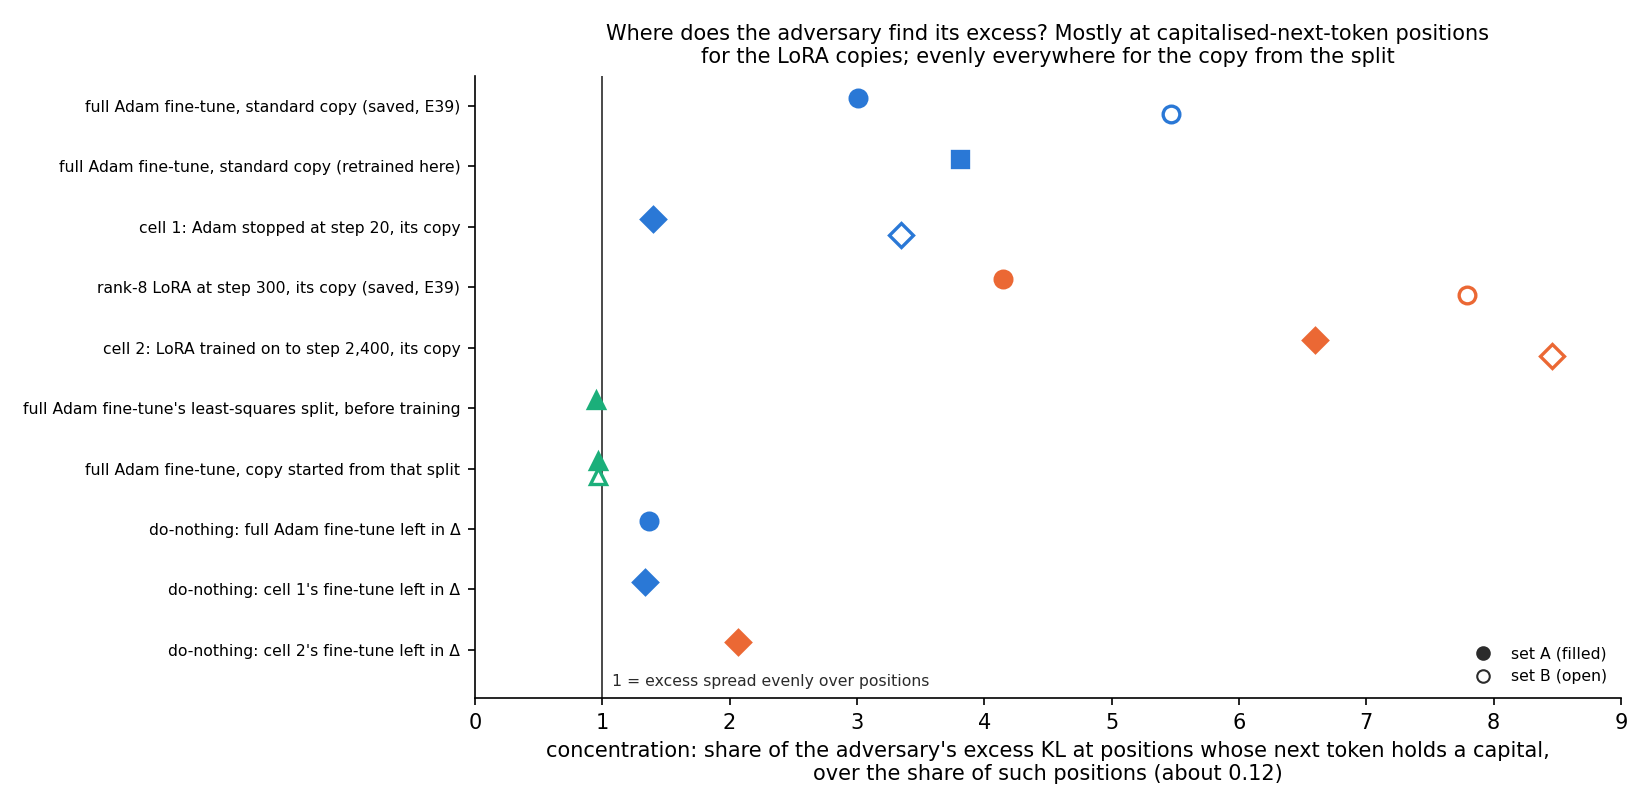

In [2]:
from IPython.display import Image

Image("../experiments/damage_crossed/figures/excess_where.png", width=820)


**Reading it.** The LoRA copies keep their excess at the case positions, and the failing Adam copies spread theirs over
ordinary text. The two LoRA copies sit at four to eight and a half times the even share. The Adam copies sit at one and
a half to five and a half. Cell 2's copy has as much excess per case position as the full Adam copy, about 2.4 nats on
set A, but almost none elsewhere: 0.09 nats against 0.59. That is why its ratio stays near the lines. The split start
and its copy sit at 1: their excess is everywhere. This is the reverse of Fable's expectation, though within the
filed noise floor for the two saved copies. It says where the adversary's KL lands, not why.


## What we learned

The crossed pair did not separate damage from recipe: both cells landed near a line. Read as a lean, the copy's ratio
moved with the update's damage under both recipes, which is what a damage cause predicts, but neither cell crossed to
the other corner's side. The Adam copies fail through small excess spread over ordinary text, while the LoRA copies
keep theirs at the positions the task changes. For `GOALS.md`'s second question, a start from the fine-tune's own
least-squares split gives a decomposition that matches the fine-tuned model but is much less faithful. Closeness to the
fine-tune in behaviour does not buy faithfulness on this task.

## How compelling is the evidence

- One adversary start and one batch order per copy. W₀'s spread over adversary starts is about 0.2 on this card, and
  both crossed cells sit within that of a line on at least one set.
- Cell 1's fail on set A rests on one block of 128 rows.
- Gain is not matched: the step-20 Adam fine-tune keeps about two thirds of the full fine-tune's lowercase gain, and
  the long LoRA run about 1.3 times the step-300 LoRA's.
- Cell 3's result is large and agrees on both sets, so more starts would not change its verdict. It is one fine-tune
  on one task.
- Blind to recipes other than a rank-8 LoRA, to SGD updates, and to where on Pile the damage sits beyond the case split.

## Surprises

**Something unexpected happened that I cannot explain: the least-squares split start reads 8.3, worse than its
do-nothing at 4.8.** The plan expected 1.0 to 1.3, as a scaled adjoint split start had read 1.05. Putting the change on
the subcomponents made the adversary's job easier than leaving it in Δ. The start fits the fine-tuned model well and is
not unusually large, so the cause is unknown. Readings built on least-squares-split starts wait until it is run down.

Smaller misses: cell 1's checkpoint came at step 20, not 50 to 150, and every cell's copy took on a damage 5 to 12%
away from its fine-tune's, outside the expected 3%. Cell 2's shortfall took it out of its band.

## What next

- **Run down the split start's 8.3.** Read the adjoint split's start on this fine-tune beside it. If the adjoint start
  reads near 1, the least-squares placement is the cause; if both read high, the broad fine-tune is.
- **The split start on the emoticon task**, planned next. If it is faithful there, the result is about broad updates.
- **More adversary starts and batch orders for cells 1 and 2.** If both settle on one side of the lines, the pair gives
  its call.


## Scorecard

Scored by the filed rules in `experiments/damage_crossed/rules.py`; nothing refiled. Full tables in
`reports/analyses/2026-11-06_analysis_e122-damage-crossed-pair.md`.

| id | claim | read | verdict |
|---|---|---|---|
| P1 | cell 1's copy passes | A 2.84 fail, B 1.44 between: mixed | not scored, unreadable |
| P2 | cell 2's copy fails | A 1.53, B 1.60, both between; copy damage 0.0009 below its band | not scored, off target and mixed |
| P3 | cell 3's copy passes | A 9.40, B 9.82, both fail; do-nothing 4.79 fails | missed |
| M1 | Adam copy's excess more concentrated than LoRA copy's | differences −1.13, −2.33 within floor 3.65 | missed: no difference |
| M2 | which of cells 1 and 2 is more concentrated | differences −5.20, −5.11 beyond floor 1.94 | reported: cell 2 more |
| outcome | damage or recipe | neither cell readable | no call |

The recipe control C5 "passed" at a ratio of 1.91 because it requires the in-job copy to **fail**, at 1.61 or above:
the control held.

## Not run

The 3e-4 LoRA fallback, not needed; Γ's on-count split of the excess; more adversary starts or batch orders; any SGD
cell; a damage grid; any narrow-task check; the split start's damage and its set B read; weight cosines on this task;
the adjoint split's start on this fine-tune.

## Provenance

`experiments/damage_crossed/results/damage_crossed.json`, filing `results/predictions.json`, run log
`~/commute-data/results-large/damage_crossed/run.log`. MATS `debug` QoS, L40, jobs 54703, 54733 and 54766 on
2026-11-06, about 54 minutes of work, $0. Results commit `c9176a07`.
